# REGRESSION ANALYSIS OF EARNINGS
- Author:- Arnold Atchoe.
- Date:- 2026-11
- Dataset:- 
- Target Feature:- Net Income as percentage of revenue(Net Income Percentage)

This model fits a line to generate regression functions for each company that predicts net income as a percentage of revenue given, cost of revenue as percentage of revenue, operating expenses as percentage of revenue and interest expense as a percentage of revenue. Regression function generated is assess using the metrics:
- RMSE:- Root mean squared error, the typical size of a miss, in the target's units.
- R-squared:- The fraction of the variation in the target the model explains (roughly 0 to 1; higher is more).
- Residual plot:- Actual minus predicted. If a straight line fits well, residuals scatter randomly around zero with no pattern. A curve or a funnel says the line is the wrong shape - itself a useful finding.

## Section 1. Project Setup and Imports

In [65]:
# Section 1a: Declare imports
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import RANSACRegressor, QuantileRegressor
from sklearn.linear_model import HuberRegressor, Lasso
from sklearn.pipeline import Pipeline
from sklearn.linear_model import TheilSenRegressor


## Section 2: Load and Prepare Regression Data

In [55]:
## Section 2a: Load data from csv file
parent_dir = Path.cwd().parent
data_dir = parent_dir / "data"
processed_data_dir = data_dir / "processed"
ml_data = pd.read_csv(processed_data_dir / "ml_data.csv")
print(ml_data.head())

## Section 2b: Specify features and target variable
feature_1 = ml_data["Cost of Revenue %"]
feature_2 = ml_data["Operating Expense %"]
target = ml_data["Net Income %"]

print(f"Features: {feature_1}, {feature_2}")
print(f"Target: {target}")

x=pd.concat([feature_1, feature_2], axis=1)
y = target

  Ticker  Cost of Revenue %  Operating Expense %  Interest Expense %  \
0    WMT          76.268193            17.239952            0.432992   
1    WMT          75.700004            17.894776            0.561306   
2    WMT          75.700172            18.455589            0.513215   
3    WMT          75.064012            18.549771            0.459301   
4    WMT          74.903747            18.217601            0.491578   

   Net Income %  
0      3.975656  
1      3.812786  
2      3.475201  
3      4.075635  
4      5.204538  
Features: 0      76.268193
1      75.700004
2      75.700172
3      75.064012
4      74.903747
         ...    
375    88.163571
376    87.686695
377    87.315708
378    87.094340
379    87.263249
Name: Cost of Revenue %, Length: 380, dtype: float64, 0      17.239952
1      17.894776
2      18.455589
3      18.549771
4      18.217601
         ...    
375     8.372751
376     8.790332
377     8.867335
378     9.027810
379     8.765918
Name: Operating Expen

## Section 3: Split into Train and Test datasets.

In [66]:
# Section 3: Prepare each ticker's data for machine learning
for ticker in ml_data["Ticker"].unique():
    ticker_data = ml_data[ml_data["Ticker"] == ticker]
    X = pd.concat([ticker_data[feature_1.name], ticker_data[feature_2.name]], axis=1)
    y = ticker_data[target.name]
# Section 3a: Set Random state
# Set a fixed seed for reproducibility
    random_state = 42

# Section 3b: Declare input and target variables as numpy arrays
    X: np.ndarray = X.to_numpy()
    y: np.ndarray = y.to_numpy()

# Section 3c: Declare training and testing arrays
    X_train:np.ndarray
    y_train:np.ndarray
    X_test:np.ndarray
    y_test:np.ndarray

# Section 3d: Split data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=random_state
    )

    print(f"{ticker}: len(X_train)={len(X_train)}, len(X_test)={len(X_test)}")

WMT: len(X_train)=63, len(X_test)=16
TGT: len(X_train)=56, len(X_test)=14
DLTR: len(X_train)=63, len(X_test)=16
DG: len(X_train)=63, len(X_test)=16
COST: len(X_train)=58, len(X_test)=15


## Section 4: Fit a Straight Line


  Ticker      Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  \
0    WMT     RANSAC    0.966825   0.449929   0.574157  0.320249  0.321500   
1    WMT  Theil-Sen    0.966265   0.492687   0.556118  0.324754  0.322286   
2    WMT      Huber    0.975729   0.508042   0.559224  0.329832  0.308945   
3    WMT   Quantile    1.206265   0.938502   0.704869  0.675383 -0.056183   

    Test R²  
0  0.747831  
1  0.697625  
2  0.678484  
3 -0.097170  


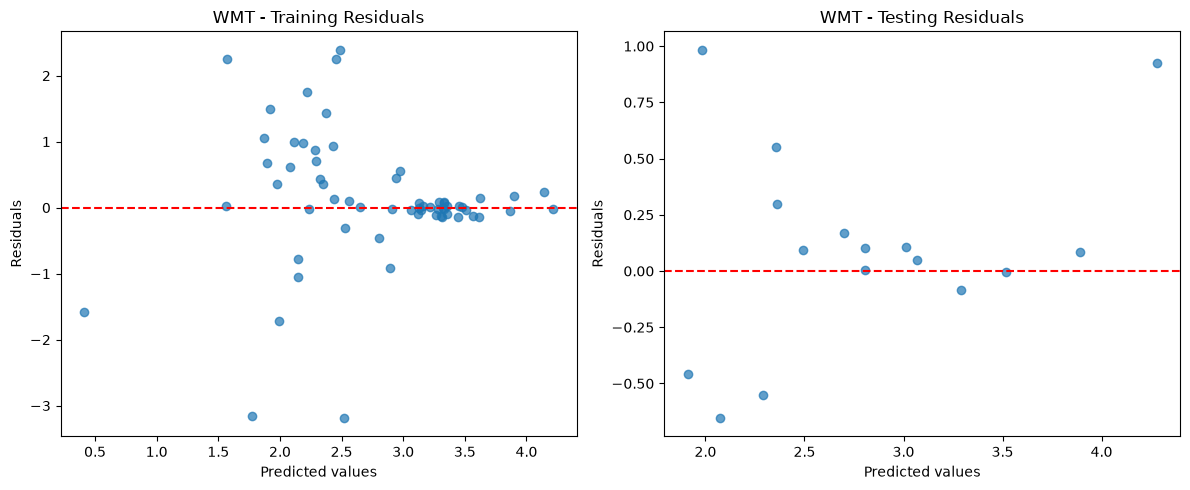

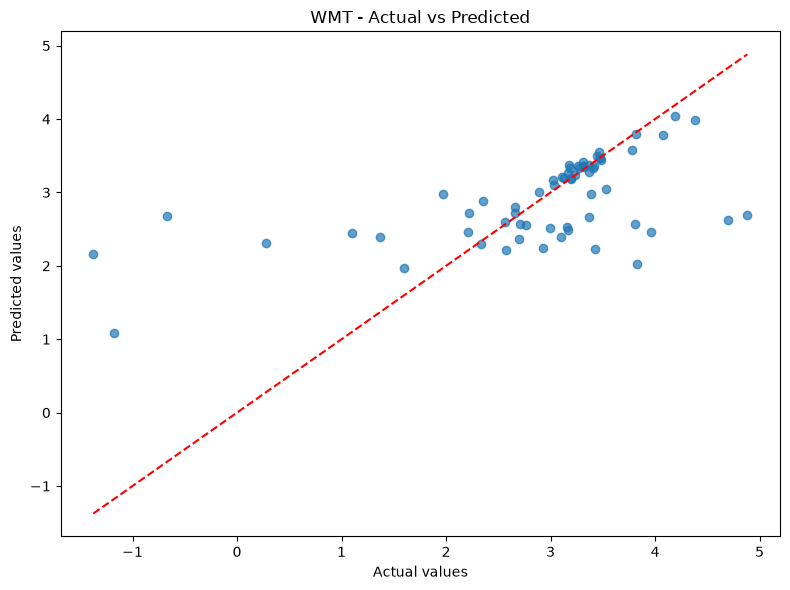

Best model: Pipeline(steps=[('scaler', StandardScaler()),
                ('regressor', TheilSenRegressor(random_state=42))])
WMT:
Coefficients: [-0.59058488 -0.58429348]
Intercept: 58.95716240614921
(-0.5906 * x1)Regression equation: y = 58.9572 +  + (-0.5843 * x2)
  Ticker      Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  \
0    TGT     RANSAC    0.910554   5.153349   0.612932  1.796087  0.587175   
1    TGT  Theil-Sen    0.824866   5.324154   0.600973  1.801583  0.661217   
2    TGT      Huber    0.776298   5.439536   0.612589  1.860818  0.699938   
3    TGT   Quantile    1.418632   4.574581   0.960980  1.836648 -0.002061   

    Test R²  
0 -0.383480  
1 -0.476709  
2 -0.541407  
3 -0.090175  


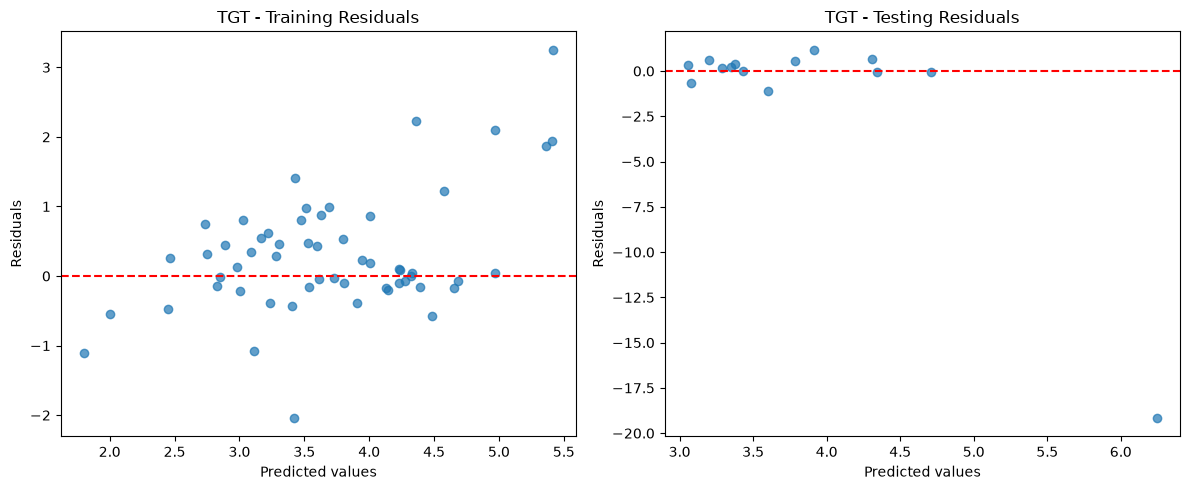

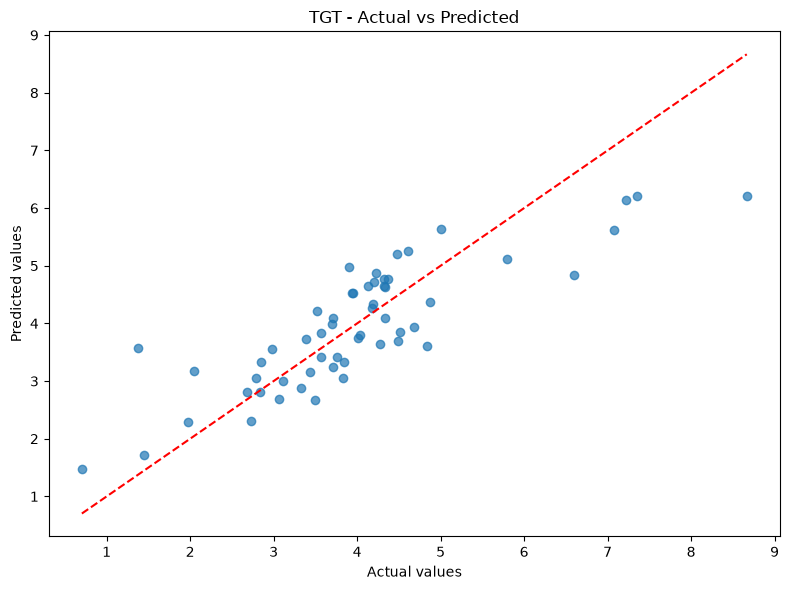

Best model: Pipeline(steps=[('scaler', StandardScaler()), ('regressor', HuberRegressor())])
TGT:
Coefficients: [-0.54700219 -0.72113628]
Intercept: 59.22539356557569
(-0.5470 * x1)Regression equation: y = 59.2254 +  + (-0.7211 * x2)
  Ticker      Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  \
0   DLTR     RANSAC    5.396920  22.977335   1.574307  8.664721 -0.805521   
1   DLTR  Theil-Sen    5.228403  22.922207   1.524059  8.553061 -0.694528   
2   DLTR      Huber    5.074471  22.920501   1.505493  8.589867 -0.596217   
3   DLTR   Quantile    4.016792  22.666285   2.249305  9.321508 -0.000160   

    Test R²  
0 -0.186197  
1 -0.180512  
2 -0.180336  
3 -0.154299  


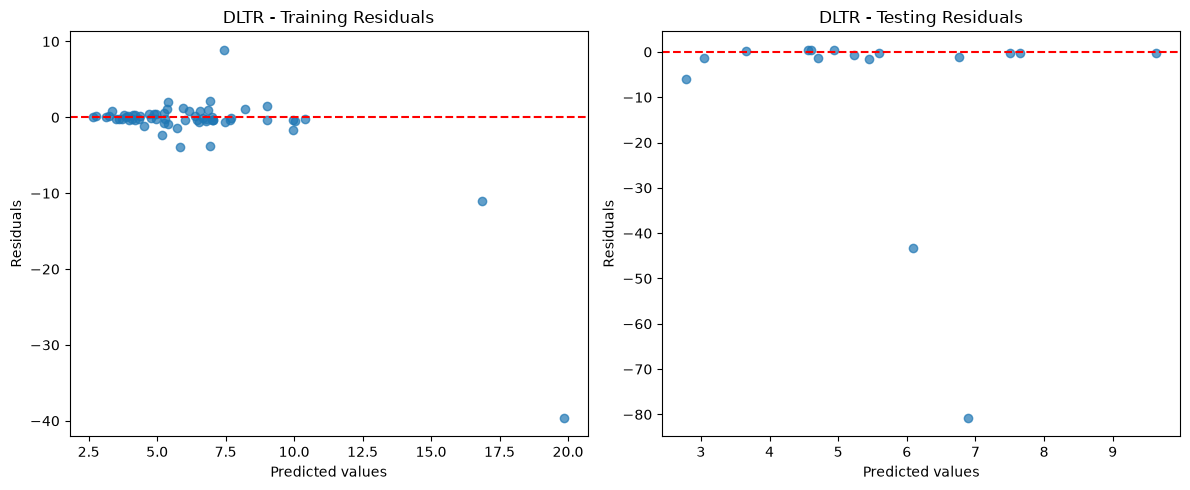

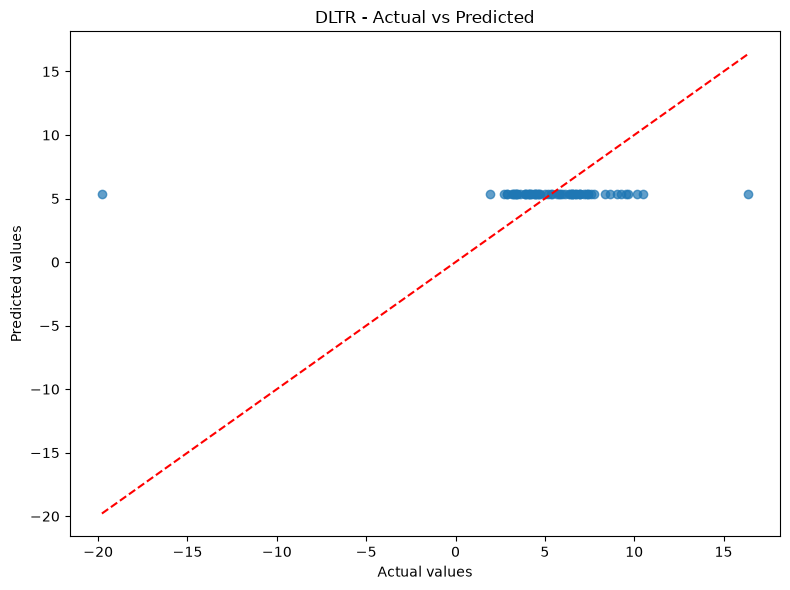

Best model: Pipeline(steps=[('scaler', StandardScaler()),
                ('regressor', QuantileRegressor())])
DLTR:
Coefficients: [0. 0.]
Intercept: 5.374090113332719
(0.0000 * x1)Regression equation: y = 5.3741 +  + (0.0000 * x2)
  Ticker      Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  \
0     DG     RANSAC    1.459316   0.876098   1.015893  0.686992  0.638812   
1     DG  Theil-Sen    1.358815   0.889815   0.999515  0.700109  0.686848   
2     DG      Huber    1.330885   1.019793   0.974617  0.767978  0.699589   
3     DG   Quantile    2.445996   1.671051   1.782174  1.287556 -0.014719   

    Test R²  
0  0.723706  
1  0.714986  
2  0.625639  
3 -0.005185  


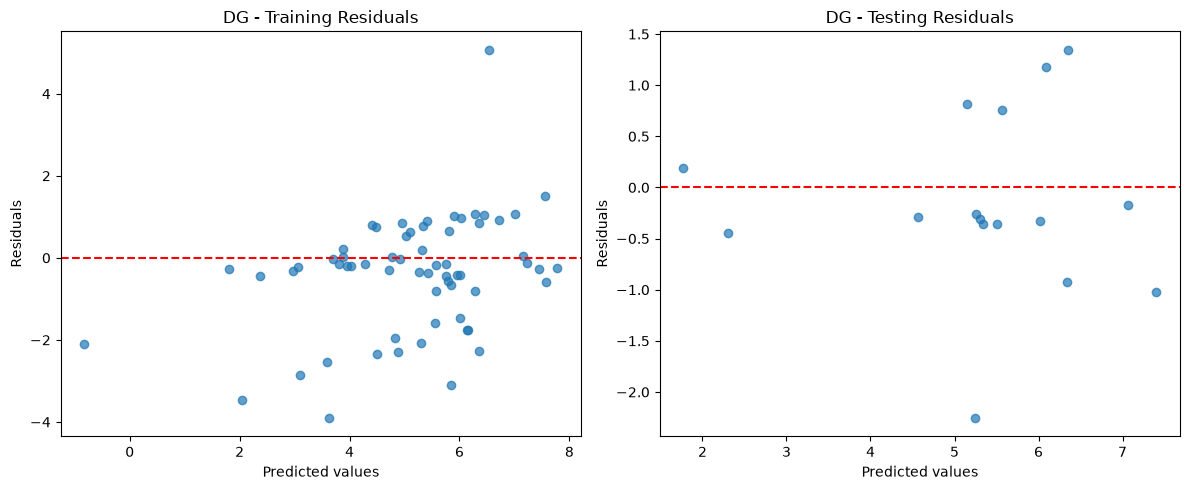

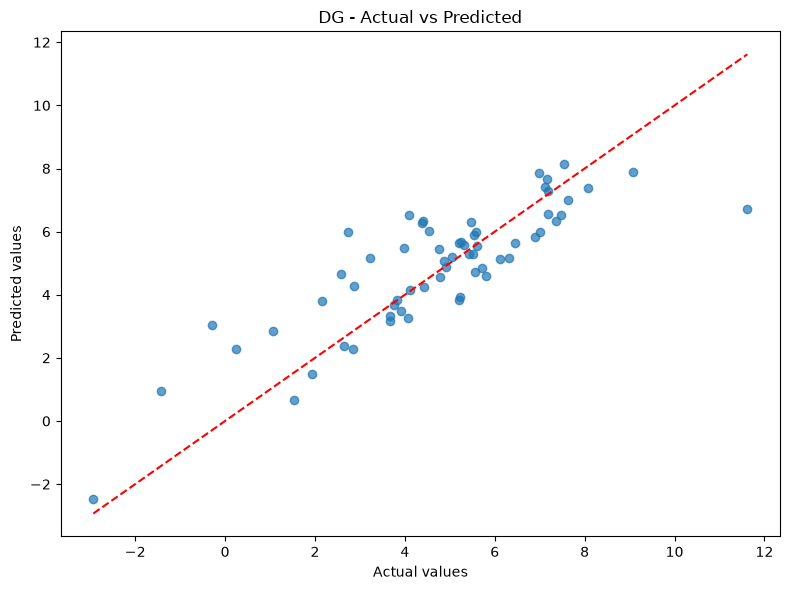

Best model: Pipeline(steps=[('scaler', StandardScaler()), ('regressor', HuberRegressor())])
DG:
Coefficients: [-0.96948533 -0.55771365]
Intercept: 84.78654206237715
(-0.9695 * x1)Regression equation: y = 84.7865 +  + (-0.5577 * x2)
  Ticker      Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R²  \
0   COST     RANSAC    0.144843   0.182157   0.113646  0.125046  0.909269   
1   COST  Theil-Sen    0.145827   0.184076   0.111742  0.124815  0.908032   
2   COST      Huber    0.145450   0.182210   0.111756  0.127686  0.908506   
3   COST   Quantile    0.485241   0.499936   0.414974  0.420764 -0.018299   

    Test R²  
0  0.857561  
1  0.854542  
2  0.857477  
3 -0.072927  


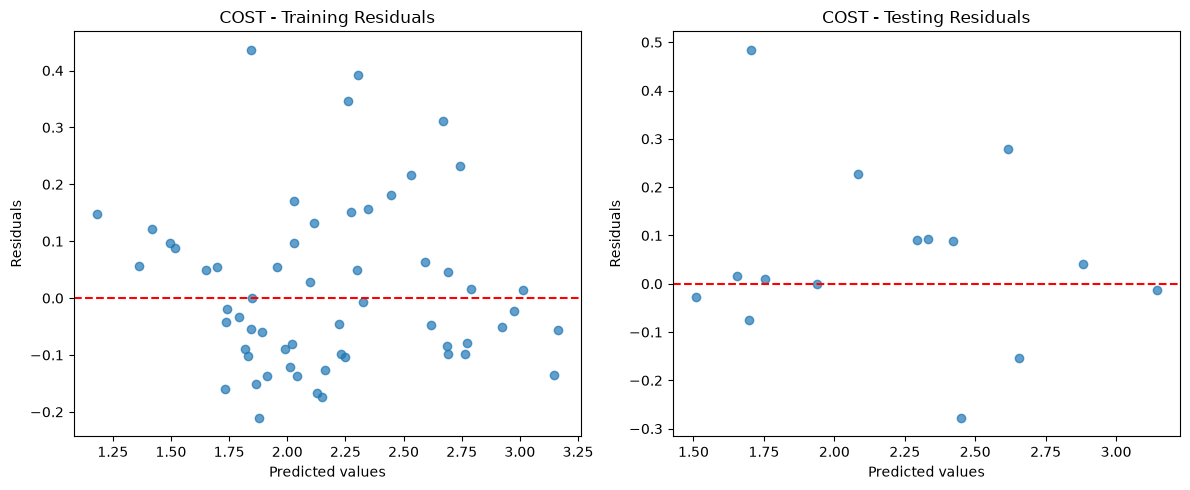

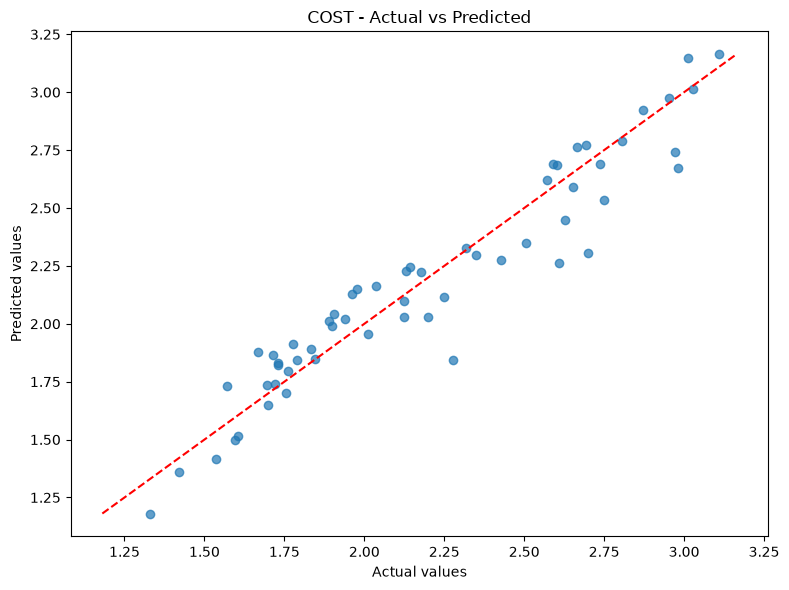

Best model: RANSACRegressor(estimator=LinearRegression(), random_state=42)
COST:
Coefficients: [-1.00619777 -1.14704146]
Intercept: 101.0040563404516
(-1.0062 * x1)Regression equation: y = 101.0041 +  + (-1.1470 * x2)


In [67]:
for ticker in ml_data["Ticker"].unique():
    ticker_data = ml_data[ml_data["Ticker"] == ticker]
    X = pd.concat([ticker_data[feature_1.name], ticker_data[feature_2.name]], axis=1)
    y = ticker_data[target.name]

    random_state = 42
    X = X.to_numpy()
    y = y.to_numpy()
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=random_state
    )

    # Fit a RANSAC, Theil-Sen, Huber regression model, and quantile regression model and compare their performance in dataframe
    model_results = []
    model_names = ["RANSAC", "Theil-Sen", "Huber", "Quantile"]
    model_1 = RANSACRegressor(estimator=LinearRegression(), random_state=random_state)
    model_1.fit(X_train, y_train)
    y_train_pred_1 = model_1.predict(X_train)
    y_test_pred_1 = model_1.predict(X_test)

    model_2 = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", TheilSenRegressor(random_state=random_state))
    ])
    model_2.fit(X_train, y_train)
    y_train_pred_2 = model_2.predict(X_train)
    y_test_pred_2 = model_2.predict(X_test)

    model_3 = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", HuberRegressor())
    ])
    model_3.fit(X_train, y_train)
    y_train_pred_3 = model_3.predict(X_train)
    y_test_pred_3 = model_3.predict(X_test)

    model_4 = Pipeline([
        ("scaler", StandardScaler()),
        ("regressor", QuantileRegressor())
    ])
    model_4.fit(X_train, y_train)
    y_train_pred_4 = model_4.predict(X_train)
    y_test_pred_4 = model_4.predict(X_test)


    # Evaluate the model's performance on the training and testing sets using RMSE, MAE and R²
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_1))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_1))
    train_mae = mean_absolute_error(y_train, y_train_pred_1)
    test_mae = mean_absolute_error(y_test, y_test_pred_1)
    train_rmse_2 = np.sqrt(mean_squared_error(y_train, y_train_pred_2))
    test_rmse_2 = np.sqrt(mean_squared_error(y_test, y_test_pred_2))
    train_mae_2 = mean_absolute_error(y_train, y_train_pred_2)
    test_mae_2 = mean_absolute_error(y_test, y_test_pred_2)
    train_rmse_3 = np.sqrt(mean_squared_error(y_train, y_train_pred_3))
    test_rmse_3 = np.sqrt(mean_squared_error(y_test, y_test_pred_3))
    train_mae_3 = mean_absolute_error(y_train, y_train_pred_3)
    test_mae_3 = mean_absolute_error(y_test, y_test_pred_3)
    train_rmse_4 = np.sqrt(mean_squared_error(y_train, y_train_pred_4))
    test_rmse_4 = np.sqrt(mean_squared_error(y_test, y_test_pred_4))
    train_mae_4 = mean_absolute_error(y_train, y_train_pred_4)
    test_mae_4 = mean_absolute_error(y_test, y_test_pred_4)

    for name, model, train_rmse_value, test_rmse_value, train_mae_value, test_mae_value in zip(
        model_names,
        [model_1, model_2, model_3, model_4],
        [train_rmse, train_rmse_2, train_rmse_3, train_rmse_4],
        [test_rmse, test_rmse_2, test_rmse_3, test_rmse_4],
        [train_mae, train_mae_2, train_mae_3, train_mae_4],
        [test_mae, test_mae_2, test_mae_3, test_mae_4],
    ):
        model_results.append({
            "Ticker": ticker,
            "Model": name,
            "Train RMSE": train_rmse_value,
            "Test RMSE": test_rmse_value,
            "Train MAE": train_mae_value,
            "Test MAE": test_mae_value,
            "Train R²": model.score(X_train, y_train),
            "Test R²": model.score(X_test, y_test),
        })

    print(pd.DataFrame(model_results))

    # Draw residual plots for the training and testing sets
    train_residuals = y_train - y_train_pred_1
    test_residuals = y_test - y_test_pred_1

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].scatter(y_train_pred_1, train_residuals, alpha=0.7)
    axes[0].axhline(0, color="red", linestyle="--")
    axes[0].set_title(f"{ticker} - Training Residuals")
    axes[0].set_xlabel("Predicted values")
    axes[0].set_ylabel("Residuals")

    axes[1].scatter(y_test_pred_1, test_residuals, alpha=0.7)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_title(f"{ticker} - Testing Residuals")
    axes[1].set_xlabel("Predicted values")
    axes[1].set_ylabel("Residuals")

    plt.tight_layout()
    plt.show()

    # Visulize regression line for the best performing model
    best_model = min(
        zip(
            [model_1, model_2, model_3, model_4],
            [train_rmse, train_rmse_2, train_rmse_3, train_rmse_4],
            [y_train_pred_1, y_train_pred_2, y_train_pred_3, y_train_pred_4],
        ),
        key=lambda result: result[1],
    )
    best_model, _, best_train_pred = best_model

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(y_train, best_train_pred, alpha=0.7)
    line_min = min(y_train.min(), best_train_pred.min())
    line_max = max(y_train.max(), best_train_pred.max())
    ax.plot([line_min, line_max], [line_min, line_max], color="red", linestyle="--")
    ax.set_title(f"{ticker} - Actual vs Predicted")
    ax.set_xlabel("Actual values")
    ax.set_ylabel("Predicted values")
    plt.tight_layout()
    plt.show()

    # print name of the best performing model
    print(f"Best model: {best_model}")

    # Print coefficients and intercept for the best performing model
    if isinstance(best_model, RANSACRegressor):
        fitted_regressor = best_model.estimator_
    elif isinstance(best_model, Pipeline):
        fitted_regressor = best_model.named_steps["regressor"]
    else:
        fitted_regressor = best_model

    coefficients = fitted_regressor.coef_
    intercept = fitted_regressor.intercept_

    if isinstance(best_model, Pipeline):
        scaler = best_model.named_steps.get("scaler")
        if scaler is not None:
            coefficients = coefficients / scaler.scale_
            intercept = intercept - np.dot(coefficients, scaler.mean_)

    print(f"{ticker}:")
    print(f"Coefficients: {coefficients}")
    print(f"Intercept: {intercept}")
    print(
        "Regression equation: y = "
        f"{intercept:.4f} + "
        " + ".join(
            f"({coef:.4f} * x{i + 1})"
            for i, coef in enumerate(coefficients)
        )
    )
   




In [58]:
# Run OLS regression with company fixed effects
import statsmodels.formula.api as smf

formula = f"Q('{target.name}') ~ Q('{feature_1.name}') + Q('{feature_2.name}') + Q('{feature_3.name}') + C(Ticker)"
ols_model = smf.ols(formula=formula, data=ml_data).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:      Q('Net Income %')   R-squared:                       0.050
Model:                            OLS   Adj. R-squared:                  0.032
Method:                 Least Squares   F-statistic:                     2.783
Date:                Sat, 21 Nov 2026   Prob (F-statistic):            0.00784
Time:                        17:49:33   Log-Likelihood:                -1155.8
No. Observations:                 380   AIC:                             2328.
Df Residuals:                     372   BIC:                             2359.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               